# Modelo de mora: explicabilidad con SHAP y LIME

## Resumen
Este cuaderno complementa el modelo temporal anterior de seis clases de mora. Mantiene el Gradient Boosting ganador (HistGradientBoosting), el mismo corte cronológico y el conjunto futuro de prueba. Añade explicabilidad global (SHAP) y local (LIME), gráficos y archivos descargables.

**Importante:** los registros son sintéticos. Las explicaciones describen patrones aprendidos, no causas. La clase de interés para los ejemplos es `MORA DE MÁS DE 90 DÍAS`; el modelo completo sigue clasificando las seis clases. La variable `mora_max_12m` requiere verificar que estaba disponible en la fecha real de predicción; si se calcula a futuro, debe excluirse por fuga de información.

## Resultados ejecutados

- En la prueba futura de junio–agosto de 2026 (2.685 filas), el modelo obtuvo **98,92 % de accuracy**, **98,37 % de balanced accuracy**, **F1 macro 98,33 %** y **log loss 0,0427**.
- En SHAP global, las señales con mayor magnitud media fueron `mora_max_3m`, `atrasos_6m_12m`, `clasif_sbs_E` y `mora_max_6m`. Debe comprobarse que estos historiales estaban disponibles al momento de predecir.
- Para el caso sintético elegido, SHAP y LIME destacaron `clasif_sbs_E`, `mora_max_3m` y `atrasos_6m_12m`; la probabilidad predicha de mora >90 días fue 100 %. **LIME alcanzó R² local 0,581**, fidelidad moderada: la explicación es aproximada y requiere cautela.
- Estos resultados corresponden a datos sintéticos. No demuestran desempeño real ni ausencia de sesgo en una cooperativa.


## Contexto y método
Se ordena por fecha: primeros 18 meses para entrenamiento, siguientes 3 meses para calibración y últimos 3 meses como prueba futura. Este cuaderno reproduce la familia de modelo elegida y explica el modelo ajustado solo con el tramo de entrenamiento. Para la visualización se explica la probabilidad de mora mayor a 90 días; SHAP/LIME operan sobre las columnas transformadas por el preprocesador, por lo que las categorías aparecen como indicadores one-hot.

### 1. Preparar el entorno
En Colab, instala SHAP y LIME si no están disponibles.

In [ ]:
# Se instalan las bibliotecas de explicabilidad si el entorno aún no las tiene.
%pip -q install shap lime

# Se importan las herramientas para datos, modelado, explicaciones y visualizaciones.
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight  # Calcula pesos balanceados solo a partir de las clases de entrenamiento.
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, log_loss
)
from IPython.display import display

# Se fijan las semillas y el estilo de gráficos para reproducibilidad.
SEMILLA = 42
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120
warnings.filterwarnings("ignore", category=FutureWarning)


### 2. Cargar los datos
Carga el CSV maestro que se generó anteriormente. En Colab aparecerá el selector de archivos.

In [ ]:
# Se solicita el archivo CSV maestro cuando se ejecuta el cuaderno en Google Colab.
try:
    from google.colab import files
    archivos_subidos = files.upload()
    ruta_csv = next((nombre for nombre in archivos_subidos if nombre.lower().endswith(".csv")), None)
except ImportError:
    # En un entorno local se usa la ruta esperada junto al cuaderno.
    ruta_csv = "dataset_mora_completo_para_modelo_temporal.csv"

# Se detiene la ejecución con una instrucción clara si no se seleccionó un CSV.
if ruta_csv is None or not os.path.exists(ruta_csv):
    raise FileNotFoundError("Sube dataset_mora_completo_para_modelo_temporal.csv y vuelve a ejecutar esta celda.")

# Se lee la fecha como fecha calendario y se valida el tamaño y las columnas clave.
datos = pd.read_csv(ruta_csv, parse_dates=["fecha_reporte"])
assert {"fecha_reporte", "mora"}.issubset(datos.columns), "Faltan fecha_reporte o mora en el CSV."
print(f"Filas: {len(datos):,} | Columnas: {datos.shape[1]} | Fechas: {datos.fecha_reporte.min().date()} a {datos.fecha_reporte.max().date()}")
display(datos.head(3))


### 3. Validar el corte temporal y las variables
Se excluyen el identificador, la fecha y `atraso` (variable objetivo auxiliar). Se revisa explícitamente la disponibilidad temporal de las variables de historial.

In [ ]:
# Se ordenan los registros para construir particiones que respeten el tiempo.
datos = datos.sort_values("fecha_reporte").reset_index(drop=True)
meses = np.array(sorted(datos["fecha_reporte"].dt.to_period("M").unique()))
assert len(meses) >= 24, "Se requieren al menos 24 meses para mantener el diseño temporal previo."

# Se conservan los mismos tramos de 18 meses de desarrollo, 3 de calibración y 3 de prueba futura.
meses_entrenamiento = meses[:18]
meses_calibracion = meses[18:21]
meses_prueba = meses[21:24]

# Se asignan registros a cada tramo según el mes de reporte.
mes_registro = datos["fecha_reporte"].dt.to_period("M")
mascara_train = mes_registro.isin(meses_entrenamiento)
mascara_cal = mes_registro.isin(meses_calibracion)
mascara_test = mes_registro.isin(meses_prueba)

# Se separan predictores y objetivo, evitando el identificador y columnas de fecha/etiqueta.
columnas_excluidas = ["ID", "fecha_reporte", "atraso", "mora"]
columnas_variables = [col for col in datos.columns if col not in columnas_excluidas]
X_train = datos.loc[mascara_train, columnas_variables].copy()
y_train = datos.loc[mascara_train, "mora"].astype(str)
X_cal = datos.loc[mascara_cal, columnas_variables].copy()
y_cal = datos.loc[mascara_cal, "mora"].astype(str)
X_test = datos.loc[mascara_test, columnas_variables].copy()
y_test = datos.loc[mascara_test, "mora"].astype(str)

# Se identifican variables numéricas y categóricas para imputarlas dentro del preprocesador.
columnas_numericas = X_train.select_dtypes(include=np.number).columns.tolist()
columnas_categoricas = [col for col in columnas_variables if col not in columnas_numericas]
print("Meses de entrenamiento:", meses_entrenamiento[0], "a", meses_entrenamiento[-1])
print("Meses de prueba futura:", meses_prueba[0], "a", meses_prueba[-1])
print("Tamaños train/calibración/test:", len(X_train), len(X_cal), len(X_test))
print("Variables potencialmente sensibles al tiempo:", [v for v in columnas_variables if "mora_max" in v or "atraso" in v])
display(y_train.value_counts(normalize=True).rename("proporción de entrenamiento").to_frame())


### 4. Entrenar el modelo ganador
El preprocesamiento se ajusta solo con el tramo de entrenamiento. No se usa calibración ni prueba para ajustar el modelo.

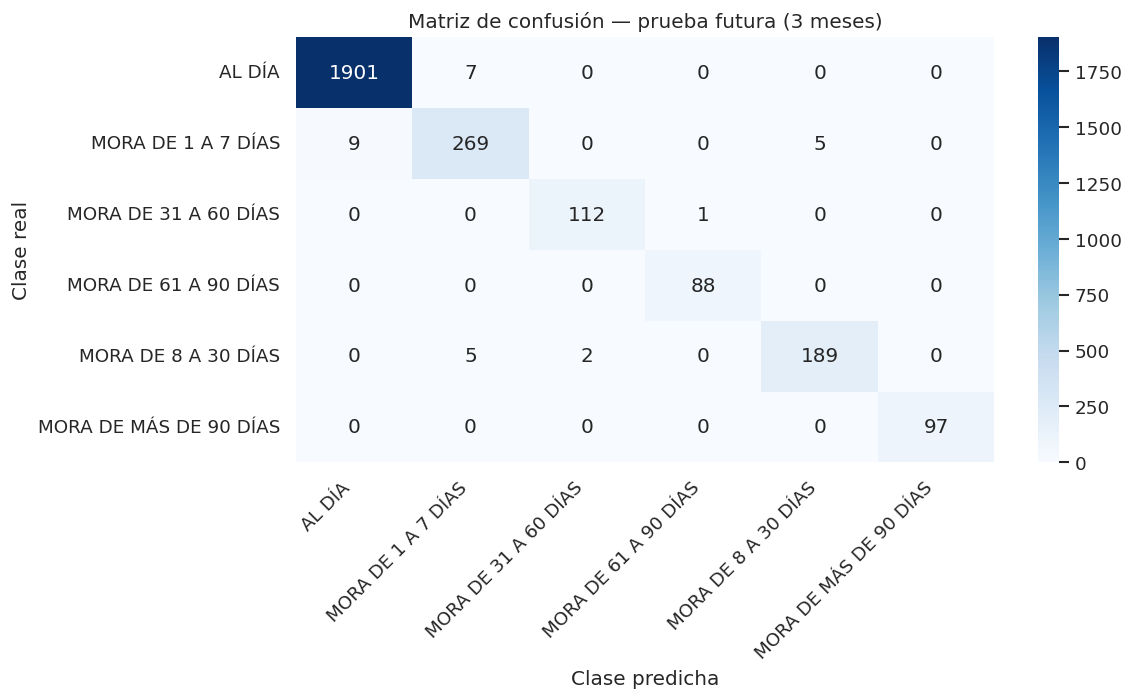

In [11]:
# Se imputan faltantes, escalan las variables numéricas y codifican las categorías.
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler())
        ]), columnas_numericas),
        ("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), columnas_categoricas)
    ],
    sparse_threshold=0
)

# Se define HistGradientBoosting con la configuración del modelo ganador anterior.
clasificador = HistGradientBoostingClassifier(
    early_stopping=False,
    l2_regularization=1.0,
    learning_rate=0.08,
    max_iter=150,
    random_state=SEMILLA
)

# Se combinan transformación y clasificador para que el aprendizaje sea reproducible.
modelo = Pipeline([
    ("preprocesador", preprocesador),
    ("modelo", clasificador)
])

# Se ajusta el pipeline únicamente con los datos de los primeros 18 meses.
pesos_entrenamiento = compute_sample_weight(class_weight="balanced", y=y_train)  # Evita que la clase mayoritaria domine el ajuste.
modelo.fit(X_train, y_train, modelo__sample_weight=pesos_entrenamiento)  # Reproduce el entrenamiento ponderado del modelo ganador anterior.
print("Clases del modelo:", modelo.named_steps["modelo"].classes_)


### 5. Medir el rendimiento en la prueba futura
La prueba final se mantiene intacta durante el ajuste. Estas métricas son una repetición del corte temporal, no una validación con datos reales de una cartera bancaria.

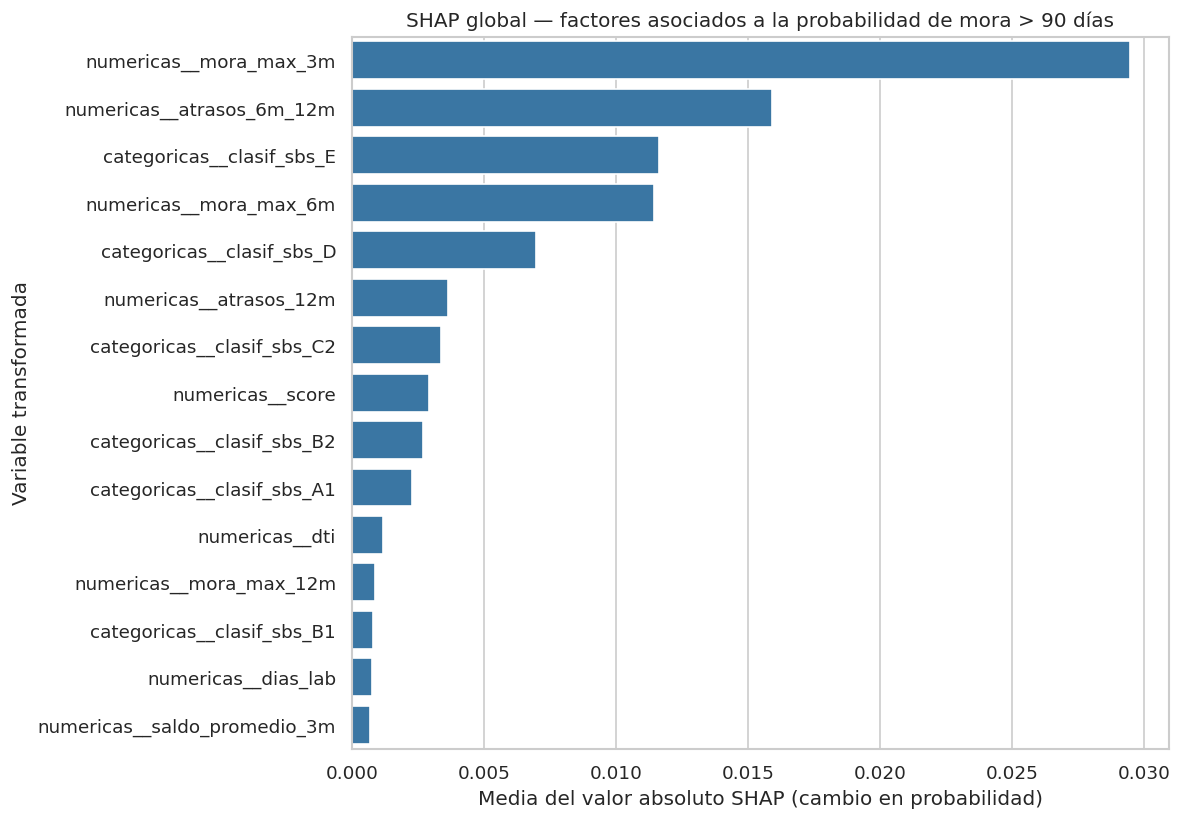

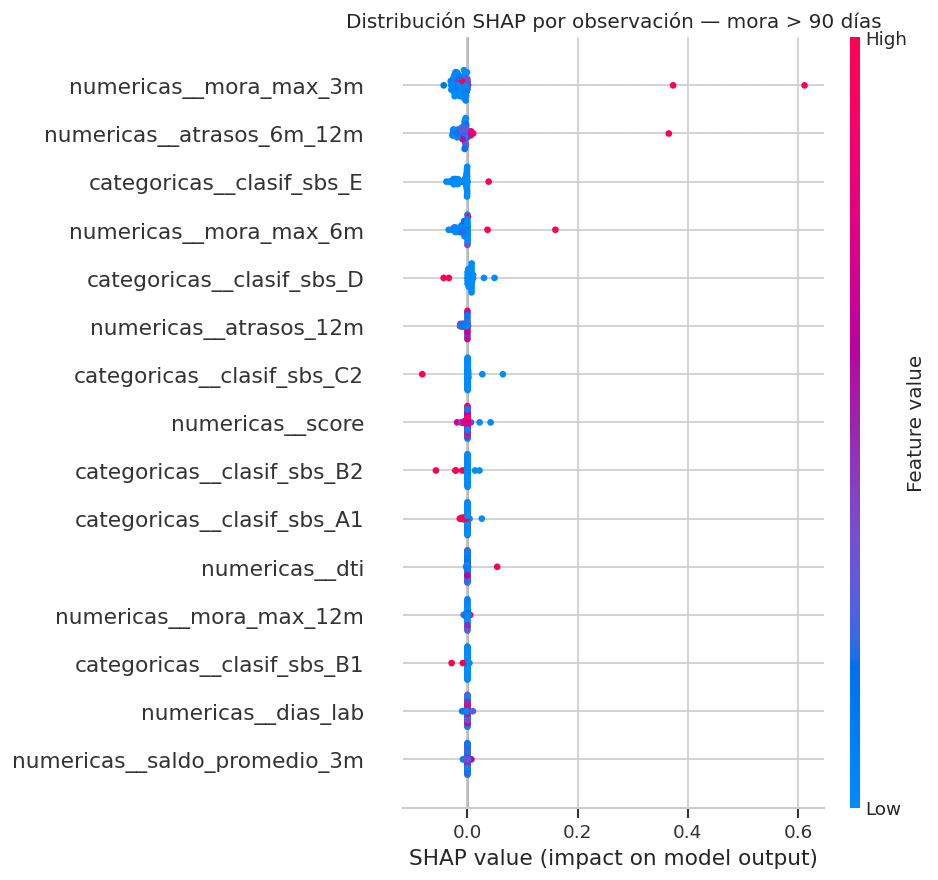

In [13]:
# Se calculan probabilidades y clases para los tres meses reservados como prueba futura.
probabilidades_test = modelo.predict_proba(X_test)
predicciones_test = modelo.predict(X_test)
clases = modelo.named_steps["modelo"].classes_

# Se resumen las métricas globales de clasificación multiclase.
metricas_test = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, predicciones_test),
    "balanced_accuracy": balanced_accuracy_score(y_test, predicciones_test),
    "precision_macro": __import__("sklearn.metrics").metrics.precision_score(y_test, predicciones_test, average="macro", zero_division=0),
    "recall_macro": __import__("sklearn.metrics").metrics.recall_score(y_test, predicciones_test, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, predicciones_test, average="macro"),
    "f1_weighted": f1_score(y_test, predicciones_test, average="weighted"),
    "log_loss": log_loss(y_test, probabilidades_test, labels=clases)
}])
display(metricas_test.round(4))

# Se dibuja la matriz de confusión para visualizar aciertos y errores por clase.
matriz = confusion_matrix(y_test, predicciones_test, labels=clases)
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases)
plt.title("Matriz de confusión — prueba futura (3 meses)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Explicabilidad global con SHAP
Se explica una salida concreta: la probabilidad estimada de `MORA DE MÁS DE 90 DÍAS`. Se utiliza un explainer agnóstico del modelo sobre la matriz ya transformada. La importancia global se calcula como el promedio del valor absoluto SHAP; esto mide asociación con las predicciones, no causalidad.

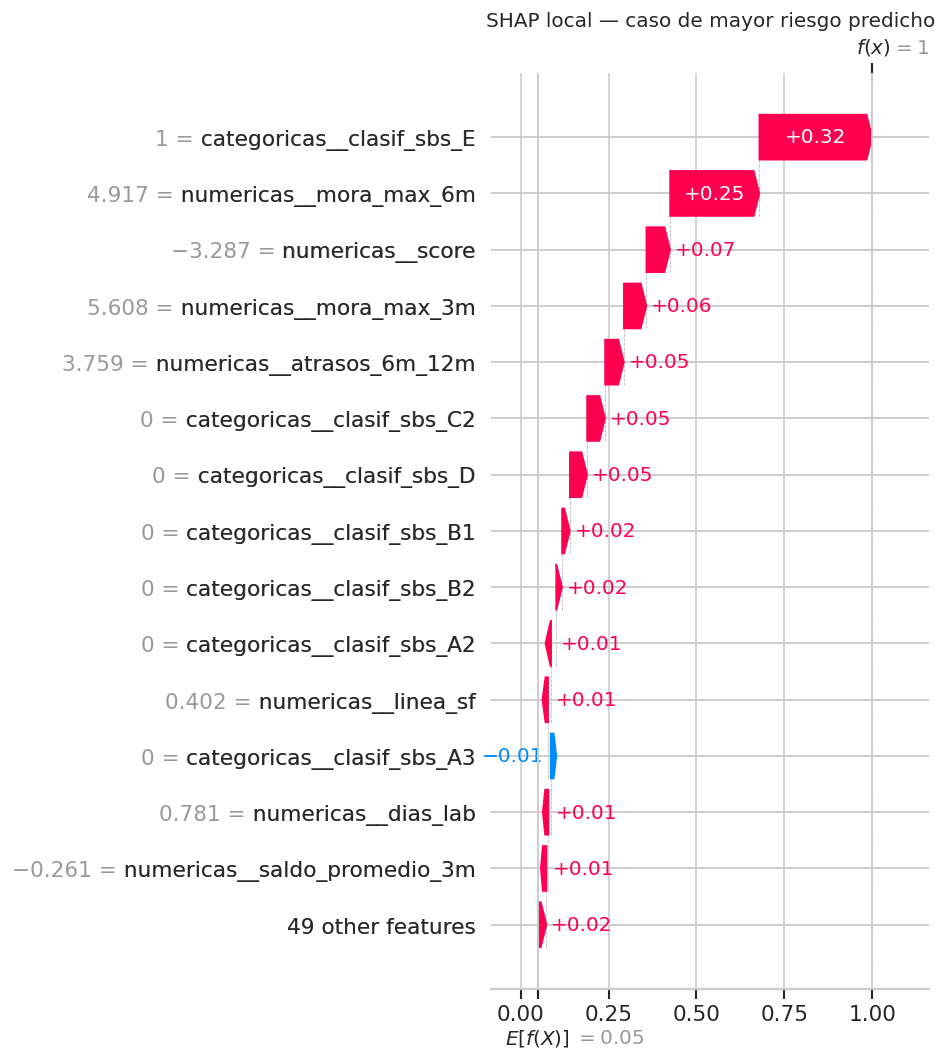

In [15]:
# Se transforma el conjunto de prueba con el mismo preprocesador aprendido en entrenamiento.
preprocesador_ajustado = modelo.named_steps["preprocesador"]
modelo_ajustado = modelo.named_steps["modelo"]
X_train_transformado = preprocesador_ajustado.transform(X_train)
X_test_transformado = preprocesador_ajustado.transform(X_test)
nombres_transformados = preprocesador_ajustado.get_feature_names_out()

# Se selecciona la clase de mora mayor a 90 días para analizar su probabilidad.
clase_objetivo = "MORA DE MÁS DE 90 DÍAS"
if clase_objetivo not in list(clases):
    raise ValueError(f"No se encontró la clase {clase_objetivo}. Clases disponibles: {list(clases)}")
indice_clase = list(clases).index(clase_objetivo)

# Se define una función que devuelve únicamente la probabilidad de la clase de interés.
def probabilidad_mora_mayor_90(matriz_transformada):
    return modelo_ajustado.predict_proba(np.asarray(matriz_transformada))[:, indice_clase]

# Se eligen muestras acotadas para que SHAP funcione en Google Colab sin un costo excesivo.
rng = np.random.default_rng(SEMILLA)
indices_fondo = rng.choice(len(X_train_transformado), size=min(40, len(X_train_transformado)), replace=False)
indices_explicacion = rng.choice(len(X_test_transformado), size=min(60, len(X_test_transformado)), replace=False)
fondo_shap = np.asarray(X_train_transformado)[indices_fondo]
muestra_shap = np.asarray(X_test_transformado)[indices_explicacion]

# Se construye el explicador por permutaciones para una salida probabilística de caja negra.
explicador_shap = shap.Explainer(
    probabilidad_mora_mayor_90,
    fondo_shap,
    algorithm="permutation",
    feature_names=nombres_transformados
)
valores_shap = explicador_shap(
    muestra_shap,
    max_evals=2 * len(nombres_transformados) + 1
)

# Se calcula importancia global con la media de valores absolutos SHAP.
importancia_shap = pd.DataFrame({
    "variable_transformada": nombres_transformados,
    "importancia_media_abs_shap": np.abs(valores_shap.values).mean(axis=0)
}).sort_values("importancia_media_abs_shap", ascending=False)
display(importancia_shap.head(15).round(5))

# Se muestran las quince variables transformadas con mayor impacto medio absoluto.
plt.figure(figsize=(10, 7))
sns.barplot(data=importancia_shap.head(15), x="importancia_media_abs_shap", y="variable_transformada", color="#2878B5")
plt.title("SHAP global — factores asociados a la probabilidad de mora > 90 días")
plt.xlabel("Media del valor absoluto SHAP (cambio en probabilidad)")
plt.ylabel("Variable transformada")
plt.tight_layout()
plt.show()

# Se inspecciona la dirección y dispersión del efecto SHAP para las variables principales.
shap.summary_plot(
    valores_shap.values,
    muestra_shap,
    feature_names=nombres_transformados,
    max_display=15,
    show=False
)
plt.title("Distribución SHAP por observación — mora > 90 días")
plt.tight_layout()
plt.show()


### 6. Explicación local con SHAP
Se selecciona de forma reproducible el caso de prueba con la mayor probabilidad predicha de mora mayor a 90 días. Este caso sirve para inspección del modelo y no representa a una persona real ni una decisión crediticia real.

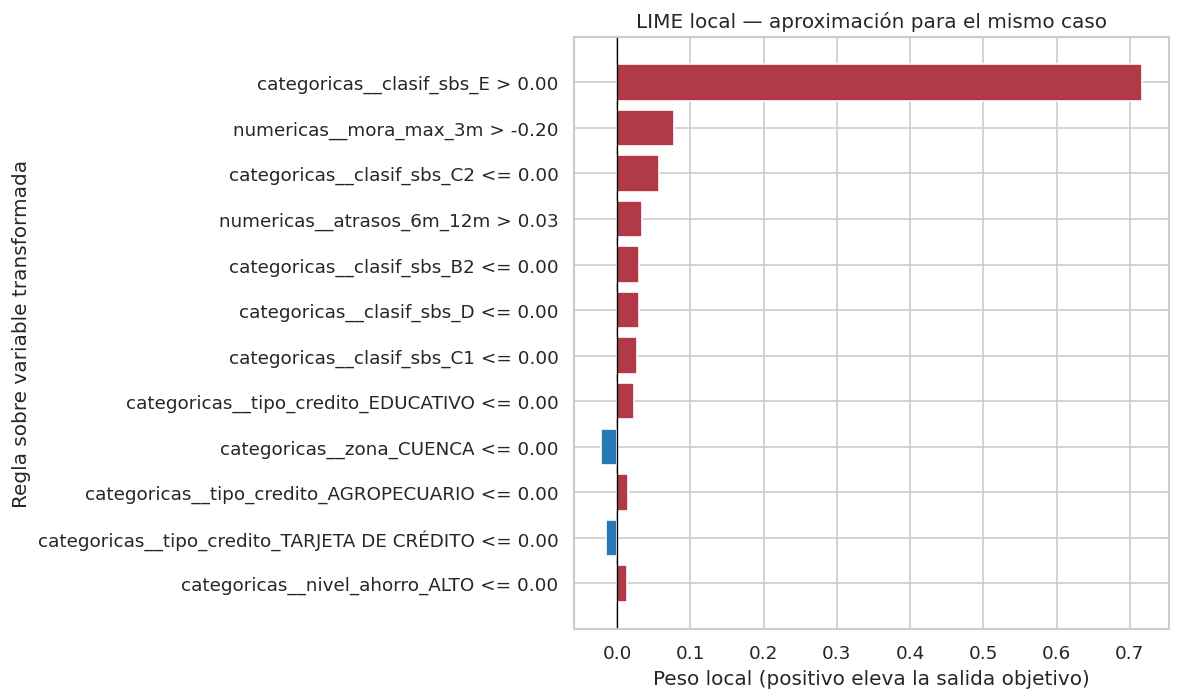

In [17]:
# Se identifica el registro de prueba con mayor probabilidad predicha de la clase objetivo.
probabilidades_objetivo = probabilidad_mora_mayor_90(X_test_transformado)
indice_caso_local = int(np.argmax(probabilidades_objetivo))
caso_transformado = np.asarray(X_test_transformado)[indice_caso_local]
probabilidad_caso = float(probabilidades_objetivo[indice_caso_local])

# Se muestran solo variables del caso y su etiqueta, sin exponer el identificador personal.
caso_original = X_test.iloc[indice_caso_local].to_dict()
resumen_caso = pd.DataFrame({
    "variable": list(caso_original.keys()),
    "valor": list(caso_original.values())
})
print(f"Probabilidad predicha de {clase_objetivo}: {probabilidad_caso:.1%}")
print(f"Clase real: {y_test.iloc[indice_caso_local]} | Clase predicha: {predicciones_test[indice_caso_local]}")
display(resumen_caso)

# Se calcula SHAP de nuevo para el mismo caso local que se explicará con LIME.
valores_shap_local = explicador_shap(
    caso_transformado.reshape(1, -1),
    max_evals=2 * len(nombres_transformados) + 1
)

# Se empaquetan los valores SHAP del caso seleccionado para crear el gráfico waterfall.
explicacion_local = shap.Explanation(
    values=valores_shap_local.values[0],
    base_values=valores_shap_local.base_values[0],
    data=caso_transformado,
    feature_names=nombres_transformados
)

# Se dibujan las contribuciones que aumentan o disminuyen la probabilidad respecto al valor base.
shap.plots.waterfall(explicacion_local, max_display=15, show=False)
plt.title("SHAP local — caso de mayor riesgo predicho")
plt.tight_layout()
plt.show()


## Explicabilidad local con LIME
LIME aproxima el comportamiento del modelo alrededor del mismo caso de prueba. Se muestran condiciones locales en variables transformadas. El R² local cuantifica la fidelidad de esa aproximación en los vecinos generados; una fidelidad baja obliga a no narrar la explicación como si fuera exacta.

In [ ]:
# Se crea el explicador LIME con datos de entrenamiento transformados y nombres de variables legibles.
limite_train = np.asarray(X_train_transformado)
limite_test = np.asarray(X_test_transformado)
explicador_lime = LimeTabularExplainer(
    training_data=limite_train,
    feature_names=list(nombres_transformados),
    class_names=list(clases),
    mode="classification",
    discretize_continuous=True,
    random_state=SEMILLA
)

# Se explica el mismo caso que se eligió para SHAP, consultando el clasificador original.
explicacion_lime = explicador_lime.explain_instance(
    data_row=limite_test[indice_caso_local],
    predict_fn=modelo_ajustado.predict_proba,
    labels=(indice_clase,),
    num_features=12,
    num_samples=3000
)

# Se convierten los pesos locales de LIME en una tabla ordenada por magnitud.
lista_lime = explicacion_lime.as_list(label=indice_clase)
tabla_lime = pd.DataFrame(lista_lime, columns=["regla_local", "peso_lime"])
tabla_lime["magnitud"] = tabla_lime["peso_lime"].abs()
tabla_lime = tabla_lime.sort_values("magnitud", ascending=False).drop(columns="magnitud")
print(f"Fidelidad local R² de LIME: {explicacion_lime.score:.3f}")
display(tabla_lime)

# Se dibujan las reglas locales positivas y negativas del modelo aproximado.
colores = ["#B23A48" if peso > 0 else "#2878B5" for peso in tabla_lime["peso_lime"]]
plt.figure(figsize=(10, 6))
plt.barh(tabla_lime["regla_local"], tabla_lime["peso_lime"], color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.title("LIME local — aproximación para el mismo caso")
plt.xlabel("Peso local (positivo eleva la salida objetivo)")
plt.ylabel("Regla sobre variable transformada")
plt.tight_layout()
plt.show()


### 7. Comparar SHAP y LIME
La coincidencia entre los métodos aporta una verificación adicional, pero ambos explican el comportamiento del mismo modelo y heredan sus limitaciones. Las diferencias pueden surgir porque SHAP distribuye contribuciones respecto a un fondo, mientras LIME ajusta un modelo lineal local.

In [ ]:
# Se ordenan las variables SHAP globales y los pesos LIME locales para una comparación auditable.
top_shap = importancia_shap.head(10)[["variable_transformada", "importancia_media_abs_shap"]].copy()
top_shap["rango_shap"] = np.arange(1, len(top_shap) + 1)
top_lime = tabla_lime.copy()
top_lime["rango_lime"] = np.arange(1, len(top_lime) + 1)
print("Top global SHAP (magnitud promedio):")
display(top_shap)
print("Top local LIME (magnitud del peso):")
display(top_lime.head(10))

# Se guarda una figura comparativa de variables presentes en las dos explicaciones.
conjunto_shap = set(top_shap["variable_transformada"])
conjunto_lime = set(top_lime["regla_local"].str.split(" [<>=]").str[0])
coincidencias = sorted(conjunto_shap & conjunto_lime)
print("Variables con coincidencia textual entre los rankings:", coincidencias)


## Auditoría de coherencia y limitaciones

- **Pregunta temporal obligatoria:** ¿cada variable existía y se conocía al generar la predicción? Revise en especial `mora_max_3m`, `mora_max_6m`, `mora_max_12m`, `atrasos_6m_12m` y `atrasos_12m`. Si contienen información posterior al momento de decisión, hay fuga y debe retirarse el predictor y reentrenar.
- La base previa representa mora en fecha de reporte; no equivale exactamente a la definición de incumplimiento a 90 días dentro de 12 meses de la presentación.
- Los datos se indicaron como sintéticos; los resultados no son evidencia de desempeño ni equidad en una cooperativa real.
- No se incluyeron género ni otras variables de auditoría en predictores porque no forman parte del CSV del modelo; no se puede concluir que el sistema sea justo para grupos.
- SHAP y LIME describen asociaciones con predicciones, no causalidad ni justificación automática de aprobar/rechazar. Requieren revisión del área de riesgos y validación de dominio.
- El caso local es una observación sintética seleccionada por riesgo predicho; no es la Rosa ficticia de la presentación porque los esquemas y valores no coinciden.

### 8. Exportar resultados
Se guardan las explicaciones, las métricas y el modelo para que puedan revisarse fuera del notebook.

In [ ]:
# Se guardan métricas, importancias SHAP, explicación LIME y predicciones de prueba.
import joblib
metricas_test.to_csv("metricas_prueba_futura.csv", index=False)
importancia_shap.to_csv("importancia_global_shap.csv", index=False)
tabla_lime.to_csv("explicacion_local_lime.csv", index=False)
predicciones_export = pd.DataFrame({
    "clase_real": y_test.to_numpy(),
    "clase_predicha": predicciones_test,
    "probabilidad_mora_mayor_90": probabilidades_objetivo
})
predicciones_export.to_csv("predicciones_prueba_futura.csv", index=False)

# Se serializa el pipeline entrenado y el metadato mínimo para reproducir la clase explicada.
joblib.dump({
    "pipeline": modelo,
    "clase_explicada": clase_objetivo,
    "columnas_variables": columnas_variables,
    "meses_train": [str(x) for x in meses_entrenamiento],
    "meses_calibracion": [str(x) for x in meses_calibracion],
    "meses_test": [str(x) for x in meses_prueba]
}, "modelo_mora_explicable_shap_lime.joblib")

# Se muestra el listado de artefactos guardados en esta carpeta.
print("Artefactos creados:")
for nombre in [
    "metricas_prueba_futura.csv", "importancia_global_shap.csv",
    "explicacion_local_lime.csv", "predicciones_prueba_futura.csv",
    "modelo_mora_explicable_shap_lime.joblib"
]:
    print("-", nombre)
